# Session 4
## Reproducible Documents and Algorithm Design

LET'S GET GOING WITH SOME LATEX IN MD :)))))

## Rocket Equation
At time $t_0$ to rocket starts to expel gas at a
_constant mass flow rate_ $R$ meassured in kg/s
and _exhaust velocity relative to the rocket_
$v_e$ in m/s.
$$
\frac{dv}{dt} = -\frac{F}{m(t)} = -\frac{Rv_e}{m(t)}
$$ {#eq-rocket-acc}
Integrating both sides of @eq-rocket-acc from 0
to $T$ we get

### Load Data

In [1]:
# Create two lists that will contain the two separate values in the table

time = []
absorption = []

In [2]:
# Import the file

dataFile = open("data/pulse_data.csv")

# Use a for loop to fill the lists

dataFile.readline() # We don't want to read in the first row because it's just the column headers, so we read through the first line to "trash" it

for line in dataFile.readlines(): # Run a for loop through all rows of the file (with the exception of the first one cause we already ditched it)
    line = line.split(",") # Split into two lists with the "," delimeter
    time.append(float(line[0])) # Add to the time list
    absorption.append(float(line[1])) # Add to the absorption list

In [3]:
# First important to import your libraries

import numpy
from matplotlib import pyplot as plt

## Data Visualisation

Text(0, 0.5, 'Absorption (unknown units)')

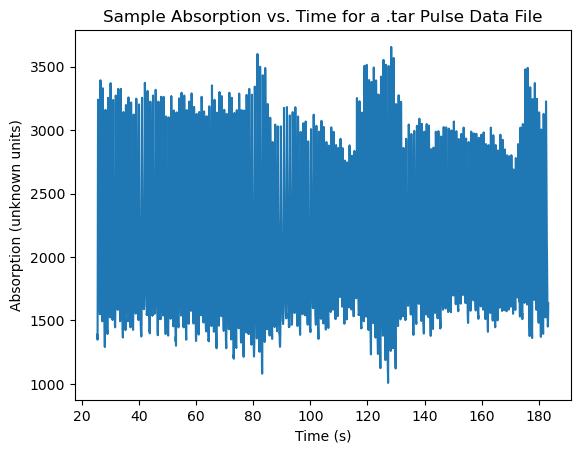

In [4]:
# TELL QUARTO WHAT TO DO WITH THIS FIGURE FOR PDF VIEWING

#| label: fig-dataset
#| fig-cap: "Measurements from an oxymetry sensor as a
#| function of time for 3 cycles"

# Create a plot using the 'time' and 'absorption' lists created earlier

plt.plot(time, absorption)
plt.title("Sample Absorption vs. Time for a .tar Pulse Data File")
plt.xlabel("Time (s)")
plt.ylabel("Absorption (unknown units)")

## Lists and Arrays Intro

In [5]:
a = numpy.arange(10)+1

In [6]:
a.shape

(10,)

In [7]:
a.dtype

# int64 means each integer require 64 bits of storage

dtype('int64')

In [8]:
a.nbytes

# there are 8 bits in a byte

80

In [9]:
b = numpy.array([[1,2,3], [4,5,6]])
b

array([[1, 2, 3],
       [4, 5, 6]])

In [10]:
b.shape

(2, 3)

In [11]:
b.T # Transpose function -- rotates the array 90 degrees

array([[1, 4],
       [2, 5],
       [3, 6]])

In [12]:
b.T @ b # @ is dot product, so this is the b-matrix squared

array([[17, 22, 27],
       [22, 29, 36],
       [27, 36, 45]])

In [13]:
a

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

In [14]:
print(numpy.max(a)) # finds the maximum value in an array
print(numpy.argmax(a)) # tells you what index the maximum value is at

10
9


## Algorithm Design

We want to find the heart rate using HR = 60/deltaTpeaks

(25.417231333621057, 25.96841821320673)

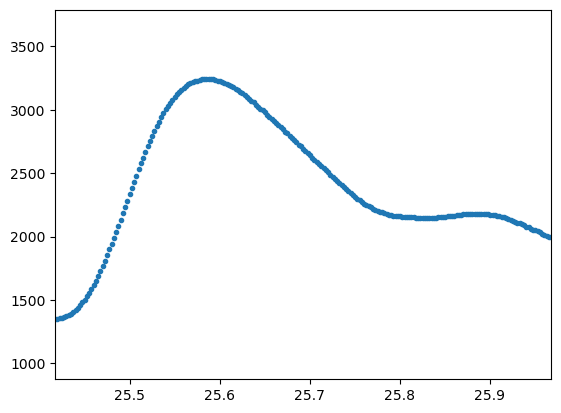

In [15]:
# Show one cycle of the PPG data

plt.plot(time, absorption, ".")
plt.xlim(time[30], time[250])

We want to be able to calculate the heart rate using a primitive technique (meaning no automatic functions). So let's try using a for loop that finds the global maximum of each cycle using a window!

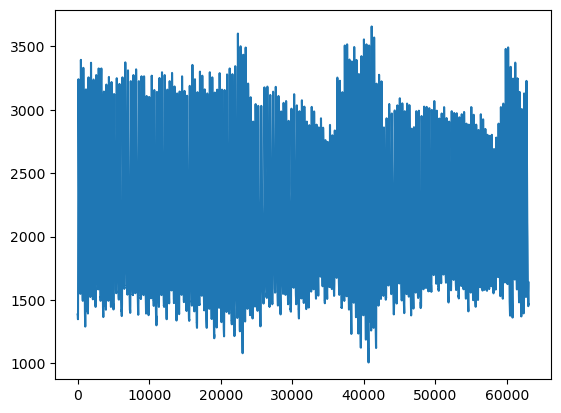

In [16]:
absorption = numpy.array(absorption) # Turn the list into a numpy array
time = numpy.array(time)
# subset = absorption[:1000] # Just take a subset to make initial testing easier
subset = absorption
w = 50 # Window for finding global maxmimum
plt.plot(subset)

In [17]:
peaks = [] # Create a new array to store the peak locations

# Create a for loop that will use a sliding window of size 2w to find the global maxima for each cycle
for i in range(len(subset)):
    start = max(i-w, 0) # Start the window at i-w unless that is negative, in which case start at 0
    end = min(i+w, len(subset)) # Stop the window at i+w unless that is greater than the length of the list, in which case end at the end
    window = subset[start:end] # Get the window
    max_pos = numpy.argmax(window) + start # Gives us the position of where the maximum lies within the for loop window.
        # "+ start" is needed in order to SHIFT the index of the position back to where it is in the actual subset
    if i == max_pos:
        peaks.append(i) # If the maximum position is where i is, then append that position to the peaks array

peaks = peaks[:-1]
# print(peaks)

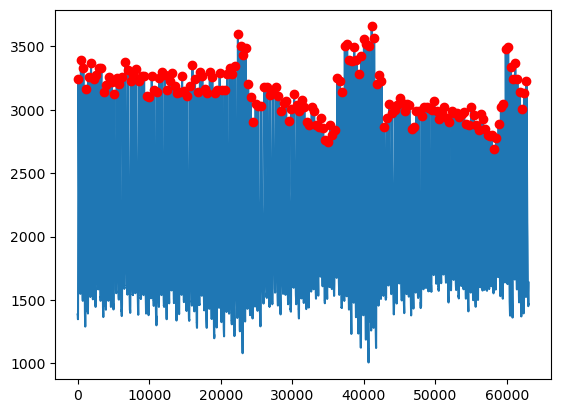

In [18]:
plt.plot(subset)
plt.plot(peaks, subset[peaks], "ro")

Now we can plot the heart rate using the time between the PPG peaks and the equation above!

Text(0, 0.5, 'Heart Rate (bpm)')

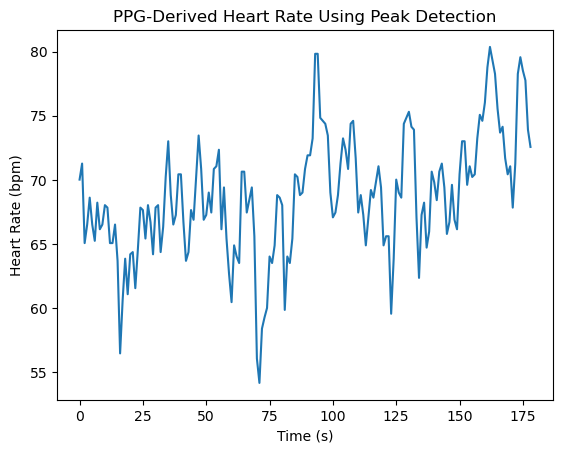

In [19]:
tp = time[peaks] # Create an array of the time at which each peak occurs
delta_t = tp[1:]-tp[:-1] # Find the time between peaks by subtracting t_n-1 from t_n
hr = 60/delta_t # Calculate the heart rate using the equation above
plt.plot(hr)
plt.title("PPG-Derived Heart Rate Using Peak Detection")
plt.xlabel("Time (s)")
plt.ylabel("Heart Rate (bpm)")